# HAM10000 Skin Lesion Classification
## Hybrid **EfficientNet-B3 + Swin-Tiny** — optimised for **Macro-F1**

**What this notebook does**

| Step | What happens |
|---|---|
| 1 | Mount Drive, set config (every setting you may want to change is in **one cell**) |
| 2 | Load your `train.csv`, `validation.csv`, `test.csv` and find the images |
| 3 | Inspect class imbalance and check for lesion leakage between splits |
| 4 | Cache images in RAM (much faster than reading Drive every epoch) |
| 5 | Build the hybrid model (CNN branch + Transformer branch, fused) |
| 6 | Handle imbalance: **weighted oversampling + class-weighted loss** (train only) |
| 7 | Train with **tqdm progress bars** (epoch bar + batch bar), early stopping on **val Macro-F1** |
| 8 | Test-time augmentation + **per-class threshold (bias) tuning on validation** to push Macro-F1 |
| 9 | One final evaluation on `test.csv`, confusion matrices, saved predictions |

**Rules followed:** validation and test are never resampled or augmented. The test set is used only once, at the very end.

## 1. Config (edit only this cell)

In [1]:
import os, random, warnings, time, json
from pathlib import Path
warnings.filterwarnings("ignore")

from google.colab import drive
drive.mount("/content/drive")

# ----------------------------- PATHS -----------------------------
BASE_DIR = "/content/drive/MyDrive/Colab Notebooks/HAM10000"   # folder with CSVs (+ images)
SAVE_DIR = "/content/drive/MyDrive/HAM10000_Project"           # outputs go here
TRAIN_CSV = os.path.join(BASE_DIR, "train_split.csv")
VAL_CSV   = os.path.join(BASE_DIR, "val_split.csv")
TEST_CSV  = os.path.join(BASE_DIR, "test_split.csv")
IMAGE_SEARCH_DIRS = [BASE_DIR]          # images are searched recursively in these folders
os.makedirs(SAVE_DIR, exist_ok=True)

# ----------------------------- TRAINING -----------------------------
SEED          = 42
IMAGE_SIZE    = 224        # 224 is safe for both backbones
CACHE_SIZE    = 256        # images are cached at this size, then cropped/resized to IMAGE_SIZE
BATCH_SIZE    = 16         # if CUDA out-of-memory -> 8
EPOCHS        = 30
PATIENCE      = 8          # early stopping on validation macro-F1
FREEZE_EPOCHS = 1          # train only the fusion head for the first N epochs
WARMUP_EPOCHS = 2          # learning-rate warm-up
NUM_WORKERS   = 2
USE_AMP       = True       # mixed precision (faster, less memory)

LR_EFFICIENTNET = 1e-4
LR_SWIN         = 5e-5
LR_HEAD         = 5e-4
WEIGHT_DECAY    = 1e-2
LABEL_SMOOTHING = 0.05
DROPOUT         = 0.4

# ----------------------------- IMBALANCE HANDLING (train only) -----------------------------
USE_WEIGHTED_SAMPLER  = True   # oversample rare classes (sampling prob ~ 1 / count**SAMPLER_STRENGTH)
SAMPLER_STRENGTH      = 0.5    # 0 = off, 0.5 = square-root (recommended), 1 = fully balanced
USE_CLASS_WEIGHTS     = True   # weighted loss (effective-number weights)
CLASS_WEIGHT_STRENGTH = 0.5    # 0 = off, 1 = full weights
LOSS_TYPE             = "ce"   # "ce" = cross-entropy, "focal" = focal loss
FOCAL_GAMMA           = 2.0

# ----------------------------- MACRO-F1 BOOSTERS -----------------------------
USE_TTA          = True    # average predictions over flips at val/test time
USE_BIAS_TUNING  = True    # tune per-class logit offsets on VALIDATION to maximise macro-F1

Mounted at /content/drive


## 2. Imports and load the three CSV files

In [2]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import models, transforms
from torchvision.models import EfficientNet_B3_Weights, Swin_T_Weights
from PIL import Image, ImageFile
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score)
import matplotlib.pyplot as plt
import seaborn as sns

ImageFile.LOAD_TRUNCATED_IMAGES = True
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
AMP_ON = (DEVICE == "cuda") and USE_AMP

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
seed_everything(SEED)
torch.backends.cudnn.benchmark = True

print("PyTorch:", torch.__version__, "| Device:", DEVICE,
      "| GPU:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "none (enable GPU: Runtime > Change runtime type)")

for p in [TRAIN_CSV, VAL_CSV, TEST_CSV]:
    assert os.path.isfile(p), f"Missing file: {p}"

train_df = pd.read_csv(TRAIN_CSV)
val_df   = pd.read_csv(VAL_CSV)
test_df  = pd.read_csv(TEST_CSV)
print("Train / Val / Test:", train_df.shape, val_df.shape, test_df.shape)
print("Columns:", train_df.columns.tolist())
display(train_df.head(3))

PyTorch: 2.11.0+cu130 | Device: cuda | GPU: Tesla T4
Train / Val / Test: (7991, 7) (1008, 7) (1016, 7)
Columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp


## 3. Detect columns and locate every image

In [3]:
def detect_column(df, candidates, required=True):
    lower = {str(c).lower(): c for c in df.columns}
    for name in candidates:
        if name.lower() in lower:
            return lower[name.lower()]
    if required:
        raise ValueError(f"No column from {candidates}. Available: {df.columns.tolist()}. "
                         "Set IMAGE_COL / LABEL_COL manually below.")
    return None

IMAGE_COL  = detect_column(train_df, ["image_path", "filepath", "file_path", "image", "image_id", "filename", "path"])
LABEL_COL  = detect_column(train_df, ["dx", "label", "diagnosis", "class", "target"])
LESION_COL = detect_column(train_df, ["lesion_id", "lesion"], required=False)
# IMAGE_COL, LABEL_COL, LESION_COL = "image_id", "dx", "lesion_id"   # <- uncomment to override
print("Image col:", IMAGE_COL, "| Label col:", LABEL_COL, "| Lesion col:", LESION_COL)

# filename -> full path index (recursive search)
EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
image_index = {}
for root in IMAGE_SEARCH_DIRS:
    for cur, _, files in os.walk(root):
        for fn in files:
            if Path(fn).suffix.lower() in EXTS:
                full = os.path.join(cur, fn)
                image_index.setdefault(fn.lower(), full)
                image_index.setdefault(Path(fn).stem.lower(), full)
print("Indexed images:", len(image_index) // 2)

def resolve_image_path(value):
    value = str(value).strip(); p = Path(value)
    if p.is_file(): return str(p)
    cand = os.path.join(BASE_DIR, value)
    if os.path.isfile(cand): return cand
    for key in (p.name.lower(), p.stem.lower()):
        if key in image_index: return image_index[key]
    raise FileNotFoundError(f"Image not found: {value}. Add its folder to IMAGE_SEARCH_DIRS.")

for name, df in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    df[LABEL_COL] = df[LABEL_COL].astype(str).str.strip().str.lower()
    df["image_path_resolved"] = df[IMAGE_COL].apply(resolve_image_path)
    print(f"{name}: {len(df)} images found")

Image col: image_id | Label col: dx | Lesion col: lesion_id
Indexed images: 10015
train: 7991 images found
validation: 1008 images found
test: 1016 images found


## 4. Class distribution and leakage check

,train,val,test
dx,,,
akiec,260,26,41
bcc,424,36,54
bkl,856,133,110
df,97,8,10
mel,877,124,112
nv,5369,663,673
vasc,108,18,16


Imbalance ratio in train (max/min): 55.4x


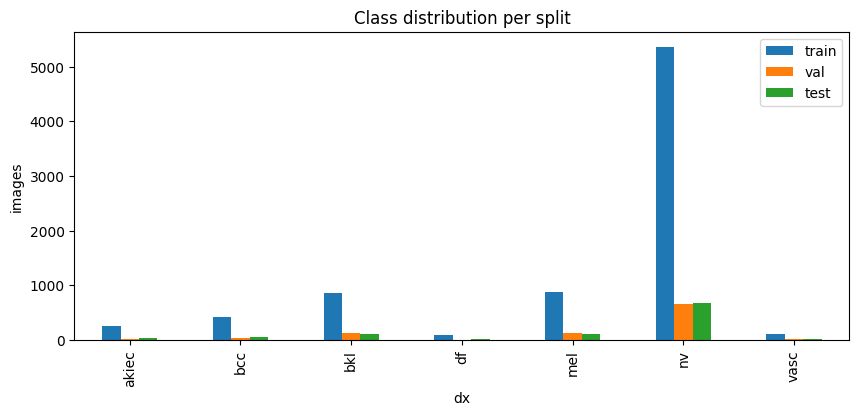

Lesion overlap  train/val: 0 | train/test: 0 | val/test: 0


In [4]:
CLASSES = sorted(train_df[LABEL_COL].unique().tolist())
class_to_idx = {c: i for i, c in enumerate(CLASSES)}
idx_to_class = {i: c for c, i in class_to_idx.items()}
NUM_CLASSES = len(CLASSES)

for name, df in [("validation", val_df), ("test", test_df)]:
    unknown = set(df[LABEL_COL]) - set(CLASSES)
    assert not unknown, f"Unknown labels in {name}: {unknown}"
for df in (train_df, val_df, test_df):
    df["target"] = df[LABEL_COL].map(class_to_idx).astype(int)

dist = pd.DataFrame({
    "train": train_df[LABEL_COL].value_counts(),
    "val":   val_df[LABEL_COL].value_counts(),
    "test":  test_df[LABEL_COL].value_counts(),
}).reindex(CLASSES).fillna(0).astype(int)
display(dist)
print(f"Imbalance ratio in train (max/min): {dist['train'].max() / dist['train'].min():.1f}x")

dist.plot(kind="bar", figsize=(10, 4), title="Class distribution per split"); plt.ylabel("images"); plt.show()

if LESION_COL is not None:
    a, b, c = (set(d[LESION_COL].astype(str)) for d in (train_df, val_df, test_df))
    print("Lesion overlap  train/val:", len(a & b), "| train/test:", len(a & c), "| val/test:", len(b & c))
    if a & b or a & c or b & c:
        print("WARNING: lesion overlap between splits -> scores will be optimistic. Prefer a lesion-grouped split.")

## 5. Cache images in RAM + augmentation + loaders

Reading ~10k images from Google Drive every epoch is very slow, so they are decoded **once** and kept as small uint8 arrays (~2 GB total).

**Imbalance handling #1 – weighted oversampling:** each training sample is drawn with probability ∝ `1 / class_count^SAMPLER_STRENGTH`, so rare classes (df, vasc, akiec) appear far more often per epoch. Oversampled copies are different every time because augmentation is random.

In [5]:
def load_resized(path):
    img = Image.open(path).convert("RGB").resize((CACHE_SIZE, CACHE_SIZE), Image.BILINEAR)
    return np.asarray(img, dtype=np.uint8)

def build_cache(df, name):
    paths = df["image_path_resolved"].tolist()
    with ThreadPoolExecutor(max_workers=16) as ex:
        arrays = list(tqdm(ex.map(load_resized, paths), total=len(paths), desc=f"Caching {name}"))
    return np.stack(arrays)

train_imgs = build_cache(train_df, "train")
val_imgs   = build_cache(val_df,   "validation")
test_imgs  = build_cache(test_df,  "test")
print("Cache size (GB):", round((train_imgs.nbytes + val_imgs.nbytes + test_imgs.nbytes) / 1e9, 2))

Caching train:   0%|          | 0/7991 [00:00<?, ?it/s]

Caching validation:   0%|          | 0/1008 [00:00<?, ?it/s]

Caching test:   0%|          | 0/1016 [00:00<?, ?it/s]

Cache size (GB): 1.97


In [6]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.7, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomApply([transforms.RandomRotation(180)], p=0.5),   # lesions have no fixed orientation
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.15, hue=0.03),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.10)),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class HAMDataset(Dataset):
    def __init__(self, images, targets, transform):
        self.images, self.targets, self.transform = images, np.asarray(targets), transform
    def __len__(self): return len(self.targets)
    def __getitem__(self, i):
        return self.transform(Image.fromarray(self.images[i])), int(self.targets[i])

train_ds = HAMDataset(train_imgs, train_df["target"].values, train_tf)
val_ds   = HAMDataset(val_imgs,   val_df["target"].values,   eval_tf)
test_ds  = HAMDataset(test_imgs,  test_df["target"].values,  eval_tf)

train_counts = np.bincount(train_df["target"].values, minlength=NUM_CLASSES)

common = dict(num_workers=NUM_WORKERS, pin_memory=(DEVICE == "cuda"),
              persistent_workers=(NUM_WORKERS > 0))

if USE_WEIGHTED_SAMPLER:
    sample_w = (1.0 / train_counts[train_df["target"].values]) ** SAMPLER_STRENGTH
    sampler = WeightedRandomSampler(torch.as_tensor(sample_w, dtype=torch.double),
                                    num_samples=len(train_ds), replacement=True)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler, drop_last=True, **common)
else:
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, **common)

val_loader  = DataLoader(val_ds,  batch_size=BATCH_SIZE * 2, shuffle=False, **common)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE * 2, shuffle=False, **common)
print("Batches  train/val/test:", len(train_loader), len(val_loader), len(test_loader))

# Sanity check: what does one epoch of the sampler look like?
if USE_WEIGHTED_SAMPLER:
    drawn = np.bincount(train_df["target"].values[list(iter(sampler))], minlength=NUM_CLASSES)
    display(pd.DataFrame({"original": train_counts, "after oversampling (1 epoch)": drawn}, index=CLASSES))

Batches  train/val/test: 499 32 32


,original,after oversampling (1 epoch)
akiec,260,695
bcc,424,850
bkl,856,1210
df,97,445
mel,877,1191
nv,5369,3125
vasc,108,475


## 6. Hybrid model: EfficientNet-B3 (local texture) + Swin-Tiny (global context)

Both backbones see the same image. Their pooled features (1536 + 768) are each normalised, concatenated, and classified by a small MLP.

In [7]:
class HybridEffSwin(nn.Module):
    def __init__(self, num_classes, dropout=0.4, pretrained=True):
        super().__init__()
        self.efficientnet = models.efficientnet_b3(weights=EfficientNet_B3_Weights.DEFAULT if pretrained else None)
        self.efficientnet.classifier = nn.Identity()
        self.swin = models.swin_t(weights=Swin_T_Weights.DEFAULT if pretrained else None)
        self.swin.head = nn.Identity()

        self.norm_eff = nn.LayerNorm(1536)
        self.norm_swin = nn.LayerNorm(768)
        self.fusion = nn.Sequential(
            nn.Linear(1536 + 768, 512), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(512, 128),        nn.GELU(), nn.Dropout(dropout),
            nn.Linear(128, num_classes),
        )

    def backbone_params(self):
        return list(self.efficientnet.features.parameters()), \
               list(self.swin.features.parameters()) + list(self.swin.norm.parameters())

    def forward(self, x):
        e = torch.flatten(self.efficientnet.avgpool(self.efficientnet.features(x)), 1)
        s = self.swin.norm(self.swin.features(x))
        s = torch.flatten(self.swin.avgpool(self.swin.permute(s)), 1)
        return self.fusion(torch.cat([self.norm_eff(e), self.norm_swin(s)], dim=1))

model = HybridEffSwin(NUM_CLASSES, dropout=DROPOUT).to(DEVICE)
model.eval()
with torch.no_grad():
    out = model(torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE))
assert out.shape == (2, NUM_CLASSES)
print("Output shape OK:", tuple(out.shape), "| Parameters (M):", round(sum(p.numel() for p in model.parameters()) / 1e6, 1))
del out

Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 143MB/s]


Downloading: "https://download.pytorch.org/models/swin_t-704ceda3.pth" to /root/.cache/torch/hub/checkpoints/swin_t-704ceda3.pth


100%|██████████| 108M/108M [00:00<00:00, 155MB/s]


Output shape OK: (2, 7) | Parameters (M): 39.5


## 7. Imbalance handling #2 – class-weighted loss, optimizer, scheduler

Weights use the **effective number of samples** (Cui et al., 2019), tempered by `CLASS_WEIGHT_STRENGTH` so rare classes are emphasised but not blown up.
Sampler + weights together give strong but controlled balancing; the per-class bias tuning in step 9 then fine-tunes the final decision thresholds.

In [8]:
beta = 0.999
eff_num = 1.0 - np.power(beta, train_counts)
w = (1.0 - beta) / np.maximum(eff_num, 1e-8)
w = w / w.mean()
w = np.power(w, CLASS_WEIGHT_STRENGTH)
w = w / w.mean()
class_weights = torch.tensor(w, dtype=torch.float32, device=DEVICE)
display(pd.DataFrame({"train_count": train_counts, "loss_weight": np.round(w, 3)}, index=CLASSES))

class FocalLoss(nn.Module):
    def __init__(self, weight=None, gamma=2.0, label_smoothing=0.0):
        super().__init__()
        self.weight, self.gamma, self.ls = weight, gamma, label_smoothing
    def forward(self, logits, target):
        ce = F.cross_entropy(logits, target, weight=self.weight, reduction="none", label_smoothing=self.ls)
        pt = torch.exp(-F.cross_entropy(logits, target, reduction="none"))
        return ((1 - pt) ** self.gamma * ce).mean()

cw = class_weights if USE_CLASS_WEIGHTS else None
if LOSS_TYPE == "focal":
    criterion = FocalLoss(cw, FOCAL_GAMMA, LABEL_SMOOTHING)
else:
    criterion = nn.CrossEntropyLoss(weight=cw, label_smoothing=LABEL_SMOOTHING)

eff_params, swin_params = model.backbone_params()
optimizer = torch.optim.AdamW([
    {"params": eff_params,  "lr": LR_EFFICIENTNET},
    {"params": swin_params, "lr": LR_SWIN},
    {"params": list(model.norm_eff.parameters()) + list(model.norm_swin.parameters()) +
               list(model.fusion.parameters()), "lr": LR_HEAD},
], weight_decay=WEIGHT_DECAY)

warmup = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=0.1, total_iters=WARMUP_EPOCHS)
cosine = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(1, EPOCHS - WARMUP_EPOCHS), eta_min=1e-7)
scheduler = torch.optim.lr_scheduler.SequentialLR(optimizer, [warmup, cosine], milestones=[WARMUP_EPOCHS])
scaler = torch.amp.GradScaler("cuda", enabled=AMP_ON)

def set_backbones_trainable(flag):
    for p in eff_params + swin_params:
        p.requires_grad = flag

,train_count,loss_weight
akiec,260,1.057
bcc,424,0.861
bkl,856,0.667
df,97,1.664
mel,877,0.662
nv,5369,0.507
vasc,108,1.581


## 8. Training with progress bars

* **Outer bar** = epochs (shows best validation macro-F1 so far)
* **Inner bar** = batches in the current epoch (live loss / accuracy)
* The best model (by **validation macro-F1**, not accuracy) is saved to Drive.

In [9]:
@torch.no_grad()
def predict_logits(loader, desc="Predict"):
    model.eval()
    outs, ys = [], []
    for x, y in tqdm(loader, desc=desc, leave=False, dynamic_ncols=True):
        x = x.to(DEVICE, non_blocking=True)
        with torch.autocast("cuda", dtype=torch.float16, enabled=AMP_ON):
            outs.append(model(x).float().cpu())
        ys.append(y)
    return torch.cat(outs), torch.cat(ys)

def train_one_epoch(epoch, backbones_frozen):
    model.train()
    if backbones_frozen:               # keep frozen backbones' BatchNorm statistics untouched
        model.efficientnet.eval(); model.swin.eval()
    loss_sum, seen, correct = 0.0, 0, 0
    preds, tgts = [], []
    bar = tqdm(train_loader, desc=f"Epoch {epoch:02d}/{EPOCHS} [train]", leave=False, dynamic_ncols=True)
    for x, y in bar:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.float16, enabled=AMP_ON):
            logits = model(x)
        loss = criterion(logits.float(), y)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer); scaler.update()

        p = logits.argmax(1)
        loss_sum += loss.item() * y.size(0); seen += y.size(0); correct += (p == y).sum().item()
        preds.append(p.cpu()); tgts.append(y.cpu())
        bar.set_postfix(loss=f"{loss_sum/seen:.4f}", acc=f"{correct/seen:.3f}")
    f1 = f1_score(torch.cat(tgts), torch.cat(preds), average="macro", zero_division=0)
    return loss_sum / seen, correct / seen, f1

CKPT_PATH = os.path.join(SAVE_DIR, "best_ham10000_hybrid.pth")
best_val_f1, best_epoch, bad_epochs = -1.0, 0, 0
history = []

epoch_bar = tqdm(range(1, EPOCHS + 1), desc="Training", dynamic_ncols=True)
for epoch in epoch_bar:
    frozen = epoch <= FREEZE_EPOCHS
    set_backbones_trainable(not frozen)
    if epoch == FREEZE_EPOCHS + 1:
        epoch_bar.write(">> Backbones unfrozen: full fine-tuning starts")

    t0 = time.time()
    tr_loss, tr_acc, tr_f1 = train_one_epoch(epoch, frozen)

    v_logits, v_y = predict_logits(val_loader, desc=f"Epoch {epoch:02d}/{EPOCHS} [val]")
    v_loss = criterion(v_logits.to(DEVICE), v_y.to(DEVICE)).item()   # weights are on GPU, so move tensors there
    v_pred = v_logits.argmax(1)
    v_acc = accuracy_score(v_y, v_pred)
    v_f1 = f1_score(v_y, v_pred, average="macro", zero_division=0)
    lr_now = optimizer.param_groups[-1]["lr"]
    scheduler.step()

    history.append(dict(epoch=epoch, train_loss=tr_loss, train_acc=tr_acc, train_macro_f1=tr_f1,
                        val_loss=v_loss, val_acc=v_acc, val_macro_f1=v_f1, lr_head=lr_now))

    improved = v_f1 > best_val_f1
    if improved:
        best_val_f1, best_epoch, bad_epochs = v_f1, epoch, 0
        torch.save({"model_state_dict": model.state_dict(), "classes": CLASSES,
                    "best_val_macro_f1": best_val_f1, "epoch": epoch}, CKPT_PATH)
    else:
        bad_epochs += 1

    epoch_bar.set_postfix(val_F1=f"{v_f1:.4f}", best=f"{best_val_f1:.4f}@{best_epoch}", patience=f"{bad_epochs}/{PATIENCE}")
    epoch_bar.write(
        f"Epoch {epoch:02d}/{EPOCHS} | {time.time()-t0:4.0f}s | "
        f"train loss {tr_loss:.4f} acc {tr_acc:.3f} F1 {tr_f1:.3f} | "
        f"val loss {v_loss:.4f} acc {v_acc:.3f} F1 {v_f1:.4f}" + ("  <- best, saved" if improved else ""))

    if bad_epochs >= PATIENCE:
        epoch_bar.write(f"Early stopping: no val macro-F1 improvement for {PATIENCE} epochs.")
        break

history_df = pd.DataFrame(history)
history_df.to_csv(os.path.join(SAVE_DIR, "training_history.csv"), index=False)
print(f"Best epoch: {best_epoch} | Best validation macro-F1: {best_val_f1:.4f}")

Training:   0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01/30 [train]:   0%|          | 0/499 [00:00<?, ?it/s]

Epoch 01/30 [val]:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch 01/30 |   98s | train loss 1.5559 acc 0.487 F1 0.393 | val loss 1.1841 acc 0.694 F1 0.4400  <- best, saved
>> Backbones unfrozen: full fine-tuning starts


Epoch 02/30 [train]:   0%|          | 0/499 [00:00<?, ?it/s]

Epoch 02/30 [val]:   0%|          | 0/32 [00:00<?, ?it/s]

... (81 outputs left out)

Epoch 29/30 |  122s | train loss 0.3631 acc 0.990 F1 0.992 | val loss 0.9253 acc 0.867 F1 0.7260


Epoch 30/30 [train]:   0%|          | 0/499 [00:00<?, ?it/s]

Epoch 30/30 [val]:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch 30/30 |  122s | train loss 0.3671 acc 0.988 F1 0.991 | val loss 0.9325 acc 0.868 F1 0.7428
Best epoch: 23 | Best validation macro-F1: 0.7670


### Training curves

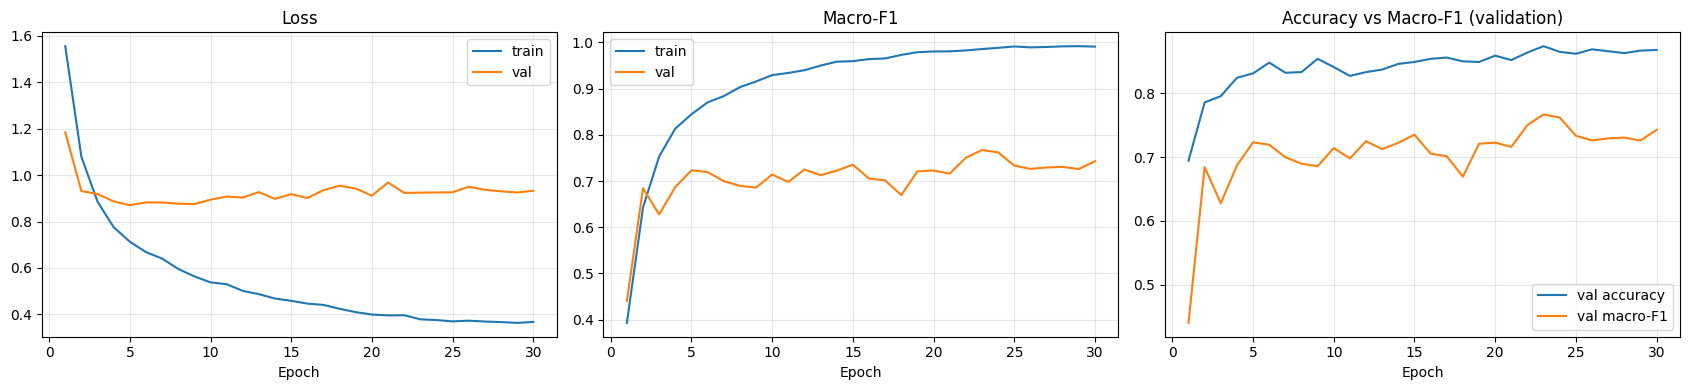

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot(history_df.epoch, history_df.train_loss, label="train"); ax[0].plot(history_df.epoch, history_df.val_loss, label="val")
ax[0].set_title("Loss"); ax[1].plot(history_df.epoch, history_df.train_macro_f1, label="train"); ax[1].plot(history_df.epoch, history_df.val_macro_f1, label="val")
ax[1].set_title("Macro-F1"); ax[2].plot(history_df.epoch, history_df.val_acc, label="val accuracy")
ax[2].plot(history_df.epoch, history_df.val_macro_f1, label="val macro-F1"); ax[2].set_title("Accuracy vs Macro-F1 (validation)")
for a in ax: a.set_xlabel("Epoch"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(SAVE_DIR, "training_curves.png"), dpi=150); plt.show()

## 9. Squeeze out more Macro-F1: TTA + per-class bias tuning

1. Reload the best checkpoint.
2. **TTA:** average probabilities over original + horizontal flip + vertical flip + both.
3. **Bias tuning:** search a small additive offset per class (on log-probabilities) that maximises Macro-F1 **on the validation set only**. This shifts decision boundaries towards rare classes without retraining.

> The same offsets are then applied to the test set. Validation is small for rare classes, so the offsets can overfit slightly. Test results are reported **with and without** tuning so you can see whether it genuinely helps.

In [11]:
ckpt = torch.load(CKPT_PATH, map_location=DEVICE)
assert ckpt["classes"] == CLASSES, "Checkpoint class order differs from current CSV labels."
model.load_state_dict(ckpt["model_state_dict"]); model.eval()
print(f"Loaded best model from epoch {ckpt['epoch']} (val macro-F1 {ckpt['best_val_macro_f1']:.4f})")

@torch.no_grad()
def predict_probs(loader, tta=True, desc="Predict"):
    model.eval()
    flips = [lambda x: x, lambda x: x.flip(3), lambda x: x.flip(2), lambda x: x.flip(2).flip(3)] if tta else [lambda x: x]
    probs, ys = [], []
    for x, y in tqdm(loader, desc=desc, leave=False, dynamic_ncols=True):
        x = x.to(DEVICE, non_blocking=True)
        acc = 0
        for f in flips:
            with torch.autocast("cuda", dtype=torch.float16, enabled=AMP_ON):
                acc = acc + torch.softmax(model(f(x)).float(), dim=1)
        probs.append((acc / len(flips)).cpu()); ys.append(y)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

def macro_f1(y, p): return f1_score(y, p, average="macro", zero_division=0)

def tune_class_bias(log_probs, y_true, grid=np.linspace(-2.0, 2.0, 41), rounds=3):
    bias = np.zeros(log_probs.shape[1])
    best = macro_f1(y_true, (log_probs + bias).argmax(1))
    for _ in range(rounds):
        changed = False
        for c in tqdm(range(log_probs.shape[1]), desc="Tuning class bias", leave=False):
            for v in grid:
                trial = bias.copy(); trial[c] = v
                s = macro_f1(y_true, (log_probs + trial).argmax(1))
                if s > best + 1e-6:
                    best, bias, changed = s, trial, True
        if not changed: break
    return bias, best

val_probs,  val_y  = predict_probs(val_loader,  USE_TTA, "Validation")
test_probs, test_y = predict_probs(test_loader, USE_TTA, "Test")

val_f1_raw = macro_f1(val_y, val_probs.argmax(1))
bias = np.zeros(NUM_CLASSES)
if USE_BIAS_TUNING:
    bias, val_f1_tuned = tune_class_bias(np.log(val_probs + 1e-9), val_y)
    print(f"Validation macro-F1: raw {val_f1_raw:.4f} -> tuned {val_f1_tuned:.4f}")
    display(pd.DataFrame({"bias": np.round(bias, 2)}, index=CLASSES).T)
else:
    print(f"Validation macro-F1 (TTA={USE_TTA}): {val_f1_raw:.4f}")
json.dump({"classes": CLASSES, "bias": bias.tolist()}, open(os.path.join(SAVE_DIR, "class_bias.json"), "w"))

Loaded best model from epoch 23 (val macro-F1 0.7670)


Validation:   0%|          | 0/32 [00:00<?, ?it/s]

Test:   0%|          | 0/32 [00:00<?, ?it/s]

Tuning class bias:   0%|          | 0/7 [00:00<?, ?it/s]

Tuning class bias:   0%|          | 0/7 [00:00<?, ?it/s]

Tuning class bias:   0%|          | 0/7 [00:00<?, ?it/s]

Validation macro-F1: raw 0.7095 -> tuned 0.8030


,akiec,bcc,bkl,df,mel,nv,vasc
bias,-2.0,0.0,-1.7,0.0,-1.6,-1.2,-2.0


## 10. Final test evaluation (run once)

In [ ]:
pred_raw   = test_probs.argmax(1)
pred_tuned = (np.log(test_probs + 1e-9) + bias).argmax(1)

summary = pd.DataFrame({
    "Accuracy":          [accuracy_score(test_y, pred_raw), accuracy_score(test_y, pred_tuned)],
    "Balanced accuracy": [balanced_accuracy_score(test_y, pred_raw), balanced_accuracy_score(test_y, pred_tuned)],
    "Macro-F1":          [macro_f1(test_y, pred_raw), macro_f1(test_y, pred_tuned)],
    "Weighted-F1":       [f1_score(test_y, pred_raw, average="weighted"), f1_score(test_y, pred_tuned, average="weighted")],
}, index=["Model (+TTA)" if USE_TTA else "Model", "Model + bias tuning"]).round(4)
display(summary)

y_pred = pred_tuned if USE_BIAS_TUNING else pred_raw
print("\nPer-class report (", "with bias tuning" if USE_BIAS_TUNING else "no bias tuning", "):\n")
labels = list(range(NUM_CLASSES))
print(classification_report(test_y, y_pred, labels=labels, target_names=CLASSES, digits=4, zero_division=0))
pd.DataFrame(classification_report(test_y, y_pred, labels=labels, target_names=CLASSES,
             output_dict=True, zero_division=0)).T.to_csv(os.path.join(SAVE_DIR, "test_classification_report.csv"))
summary.to_csv(os.path.join(SAVE_DIR, "test_summary.csv"))

cm = confusion_matrix(test_y, y_pred, labels=labels)
cm_norm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0]); ax[0].set_title("Confusion matrix (counts)")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[1], vmin=0, vmax=1); ax[1].set_title("Confusion matrix (row-normalised = recall)")
for a in ax: a.set_xlabel("Predicted"); a.set_ylabel("True")
plt.tight_layout(); plt.savefig(os.path.join(SAVE_DIR, "test_confusion_matrix.png"), dpi=200); plt.show()

## 11. Save predictions

In [13]:
pred_df = test_df[[IMAGE_COL, LABEL_COL]].copy().reset_index(drop=True)
pred_df["predicted_label"] = [idx_to_class[int(i)] for i in y_pred]
for i, c in enumerate(CLASSES):
    pred_df[f"prob_{c}"] = test_probs[:, i]
pred_df.to_csv(os.path.join(SAVE_DIR, "test_predictions.csv"), index=False)
print("Saved to:", SAVE_DIR); print(*sorted(os.listdir(SAVE_DIR)), sep="\n")

Saved to: /content/drive/MyDrive/HAM10000_Project
best_b3_s42.pth
best_b3_s7.pth
best_efficientnet_b0.pth
best_ham10000_hybrid.pth
best_model.pth
best_v2_s_s123.pth
class_bias.json
ensemble_confusion_matrix.png
ensemble_model.pth
history_b3_s42.csv
history_b3_s7.csv
history_v2_s_s123.csv
results_summary.csv
test_classification_report.csv
test_confusion_matrix.png
test_predictions.csv
test_summary.csv
train_val_test_scores.csv
training_curves.png
training_history.csv


In [14]:
FINAL_PATH = os.path.join(SAVE_DIR, "HAM10000_hybrid_final.pth")
torch.save({
    "architecture": "HybridEffSwin (EfficientNet-B3 + Swin-Tiny)",
    "model_state_dict": {k: v.cpu() for k, v in model.state_dict().items()},
    "classes": CLASSES,
    "class_to_idx": class_to_idx,
    "image_size": IMAGE_SIZE,
    "mean": MEAN, "std": STD,
    "dropout": DROPOUT,
    "class_bias": bias.tolist(),
    "use_bias_tuning": USE_BIAS_TUNING,
    "use_tta": USE_TTA,
    "best_epoch": int(ckpt["epoch"]),
    "val_macro_f1": float(ckpt["best_val_macro_f1"]),
    "test_macro_f1": float(macro_f1(test_y, y_pred)),
}, FINAL_PATH)
print(f"Saved: {FINAL_PATH}  ({os.path.getsize(FINAL_PATH) / 1e6:.1f} MB)")
_chk = torch.load(FINAL_PATH, map_location="cpu")
print("Verified. Classes:", _chk["classes"], "| test macro-F1:", round(_chk["test_macro_f1"], 4))

Saved: /content/drive/MyDrive/HAM10000_Project/HAM10000_hybrid_final.pth  (158.7 MB)
Verified. Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc'] | test macro-F1: 0.7644


## Tuning guide (if Macro-F1 is still lower than you want)

| Symptom | Try |
|---|---|
| Rare classes (`df`, `vasc`, `akiec`) have low recall | `SAMPLER_STRENGTH = 0.75`, or `LOSS_TYPE = "focal"` |
| Rare classes recalled but precision is poor | lower `SAMPLER_STRENGTH` to `0.3` or `CLASS_WEIGHT_STRENGTH` to `0.3` |
| Train F1 much higher than val F1 (overfitting) | raise `DROPOUT`, `WEIGHT_DECAY`; lower `EPOCHS` |
| Both train and val F1 low | train longer (`PATIENCE = 12`), try `IMAGE_SIZE = 288` or `300` with `BATCH_SIZE = 8` |
| CUDA out-of-memory | `BATCH_SIZE = 8`, or `IMAGE_SIZE = 192` |
| Big gap between val and test F1 | bias tuning overfit the small val set: set `USE_BIAS_TUNING = False` |

**Notes**
* No result is guaranteed; compare **Macro-F1 and per-class recall**, not accuracy.
* If the lesion-overlap warning appeared in step 4, scores are optimistic. Use a lesion-grouped split for honest numbers.
* Research/educational model only, not a clinical diagnostic tool.

In [15]:
def load_final_model(path=FINAL_PATH):
    pkg = torch.load(path, map_location=DEVICE)
    m = HybridEffSwin(len(pkg["classes"]), dropout=pkg["dropout"], pretrained=False).to(DEVICE)
    m.load_state_dict(pkg["model_state_dict"]); m.eval()
    return m, pkg

@torch.no_grad()
def predict_image(image_path, m=None, pkg=None, tta=True):
    if m is None: m, pkg = load_final_model()
    tf = transforms.Compose([transforms.Resize((pkg["image_size"], pkg["image_size"])),
                             transforms.ToTensor(), transforms.Normalize(pkg["mean"], pkg["std"])])
    x = tf(Image.open(image_path).convert("RGB")).unsqueeze(0).to(DEVICE)
    views = [x, x.flip(3), x.flip(2), x.flip(2).flip(3)] if tta else [x]
    probs = torch.stack([torch.softmax(m(v).float(), 1) for v in views]).mean(0)[0].cpu().numpy()
    scores = np.log(probs + 1e-9) + (np.array(pkg["class_bias"]) if pkg["use_bias_tuning"] else 0)
    best = int(np.argmax(scores))
    return pkg["classes"][best], dict(zip(pkg["classes"], np.round(probs, 4)))

m_loaded, pkg_loaded = load_final_model()
label, p = predict_image(test_df["image_path_resolved"].iloc[0], m_loaded, pkg_loaded)
print("Predicted:", label, "| True:", test_df[LABEL_COL].iloc[0]); print(p)

Predicted: bcc | True: bkl
{'akiec': np.float32(0.0372), 'bcc': np.float32(0.3272), 'bkl': np.float32(0.4969), 'df': np.float32(0.0372), 'mel': np.float32(0.0181), 'nv': np.float32(0.0485), 'vasc': np.float32(0.035)}


Train (no aug):   0%|          | 0/250 [00:00<?, ?it/s]

,Images,Accuracy,Balanced acc,Macro-F1,Weighted-F1,Macro precision,Macro recall
Split,,,,,,,
Train,7991,0.9977,0.9983,0.9962,0.9977,0.9942,0.9983
Validation,1008,0.8819,0.8064,0.8030,0.8782,0.8106,0.8064
Test,1016,0.8563,0.7840,0.7644,0.8520,0.7658,0.7840



Per-class F1 by split:


,Train,Validation,Test
akiec,1.0000,0.6154,0.6286
bcc,1.0000,0.8250,0.7597
bkl,0.9959,0.8455,0.7745
df,0.9848,0.7778,0.7500
mel,0.9943,0.6818,0.6010
nv,0.9985,0.9341,0.9277
vasc,1.0000,0.9412,0.9091



Train - Test macro-F1 gap: 0.232  -> large gap: overfitting


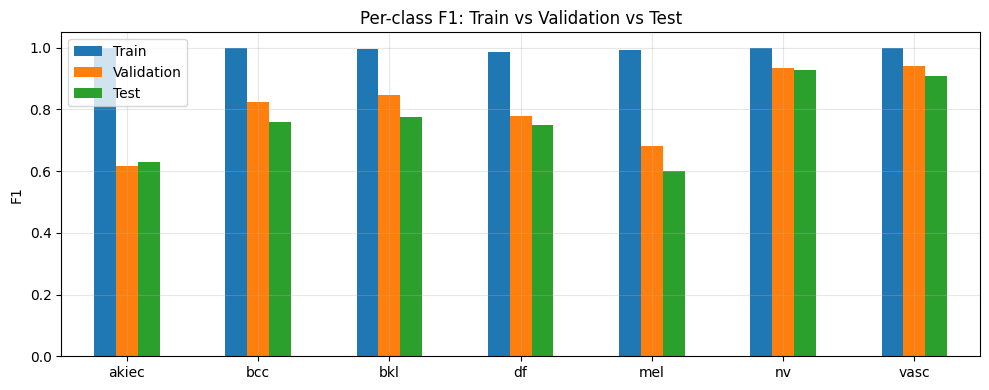

In [16]:
from sklearn.metrics import precision_score, recall_score

eval_train_ds = HAMDataset(train_imgs, train_df["target"].values, eval_tf)      # no augmentation
eval_train_loader = DataLoader(eval_train_ds, batch_size=BATCH_SIZE * 2, shuffle=False, **common)
train_probs, train_y = predict_probs(eval_train_loader, USE_TTA, "Train (no aug)")

def final_pred(probs):
    return (np.log(probs + 1e-9) + bias).argmax(1) if USE_BIAS_TUNING else probs.argmax(1)

splits = {"Train": (train_probs, train_y), "Validation": (val_probs, val_y), "Test": (test_probs, test_y)}
rows, per_class = [], {}
for name, (pr, yy) in splits.items():
    pp = final_pred(pr)
    rows.append({
        "Split": name, "Images": len(yy),
        "Accuracy": accuracy_score(yy, pp),
        "Balanced acc": balanced_accuracy_score(yy, pp),
        "Macro-F1": f1_score(yy, pp, average="macro", zero_division=0),
        "Weighted-F1": f1_score(yy, pp, average="weighted", zero_division=0),
        "Macro precision": precision_score(yy, pp, average="macro", zero_division=0),
        "Macro recall": recall_score(yy, pp, average="macro", zero_division=0),
    })
    per_class[name] = f1_score(yy, pp, labels=list(range(NUM_CLASSES)), average=None, zero_division=0)

results_df = pd.DataFrame(rows).set_index("Split").round(4)
display(results_df)
results_df.to_csv(os.path.join(SAVE_DIR, "train_val_test_results.csv"))

print("\nPer-class F1 by split:")
pc_df = pd.DataFrame(per_class, index=CLASSES).round(4)
display(pc_df)
pc_df.to_csv(os.path.join(SAVE_DIR, "per_class_f1_by_split.csv"))

gap = results_df.loc["Train", "Macro-F1"] - results_df.loc["Test", "Macro-F1"]
print(f"\nTrain - Test macro-F1 gap: {gap:.3f}  ->",
      "small gap, little overfitting" if gap < 0.08 else "moderate gap" if gap < 0.15 else "large gap: overfitting")

ax = pc_df.plot(kind="bar", figsize=(10, 4), title="Per-class F1: Train vs Validation vs Test")
ax.set_ylabel("F1"); ax.set_ylim(0, 1.05); ax.grid(alpha=.3); plt.xticks(rotation=0); plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "per_class_f1_by_split.png"), dpi=150); plt.show()